# Bước 2.5 — Phân lớp khoảng lương chào tuyển trong phạm vi IT

Trong phần này, nhóm sử dụng kỹ năng và kinh nghiệm để dự đoán nhóm của **trung điểm khoảng lương chào tuyển** đã xử lý. Đây không phải lương thực nhận của ứng viên.

Nhóm giữ lại cách xây dựng pipeline, chia nhóm và so sánh ba mô hình của phiên bản trước. Phần bổ sung là kiểm tra `scope_status`, chỉ dùng tin thuộc `included_provisional`, sửa scorer và cập nhật kết quả theo tập dữ liệu sau lọc.

`included_provisional` là phạm vi IT được chấp nhận sơ bộ; các tin `pending_review` tạm thời chưa dùng vì còn chờ rà soát. Việc loại này không có nghĩa tất cả tin chờ rà soát đều ngoài ngành IT.

**Chạy trên máy thành viên:** mở notebook trong thư mục `buoc 2.5_Portable/` của repo (hoặc gói độc lập có kèm `buoc2.1_2.2/`), cài thư viện theo `requirements.txt` và chọn Restart & Run All. Dữ liệu được tìm theo đường dẫn tương đối; kết quả luôn nằm trong `output_salary_scope/` cạnh notebook.

**Quy ước nhóm:** dùng bản `buoc 2.5_Portable/Classification_HoanChinh.ipynb` trong repository hiện tại. CSV lấy ở `buoc2.1_2.2/data/processed/clean_data_processed.csv` từ gốc repo; toàn bộ đầu ra nằm trong `buoc 2.5_Portable/output_salary_scope`. Mỗi thành viên có thể lưu repo ở ổ đĩa khác nhau.


In [1]:
from pathlib import Path
import sys, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             make_scorer)
SEED = 42
# Cấu trúc dùng chung cho cả nhóm: một gốc repo, một CSV và một nơi xuất.
# Không nhập đường dẫn ổ D của một thành viên vào code dùng chung.
PROJECT_ROOT_OVERRIDE = None  # Chỉ đặt nếu kernel mở ngoài cây thư mục dự án.
REL_DATA = Path("buoc2.1_2.2/data/processed/clean_data_processed.csv")
PORTABLE_DIR = "buoc 2.5_Portable"
NOTEBOOK_NAME = "Classification_HoanChinh.ipynb"

if PROJECT_ROOT_OVERRIDE is not None:
    PROJECT_ROOT = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
else:
    search_dirs = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    # Phải có cả Portable và CSV ở gốc repo. Không chọn bản CSV lồng trong Portable.
    PROJECT_ROOT = next((folder for folder in search_dirs
                         if (folder / PORTABLE_DIR).is_dir()
                         and (folder / REL_DATA).is_file()), None)
    if PROJECT_ROOT is None:
        raise FileNotFoundError(
            "Không tìm thấy gốc dự án có cả buoc 2.5_Portable/ và "
            "buoc2.1_2.2/data/processed/clean_data_processed.csv. "
            "Hãy mở gốc repo hoặc thư mục Portable; nếu kernel ở nơi khác, "
            "đặt PROJECT_ROOT_OVERRIDE tới gốc repo của bạn."
        )

DATA_PATH = PROJECT_ROOT / REL_DATA
NOTEBOOK_DIR = PROJECT_ROOT / PORTABLE_DIR
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Thiếu CSV tại: {DATA_PATH}")
if not (NOTEBOOK_DIR / NOTEBOOK_NAME).is_file():
    raise FileNotFoundError(
        f"Cần notebook tên {NOTEBOOK_NAME} trong {NOTEBOOK_DIR}. "
        "Nếu đã đổi tên file, hãy cập nhật NOTEBOOK_NAME cho khớp."
    )
RESULT_DIR = NOTEBOOK_DIR / "output_salary_scope"
print("Thư mục làm việc:", Path.cwd())
print("Gốc dự án dùng chung:", PROJECT_ROOT)
print("CSV duy nhất được sử dụng:", DATA_PATH)
print("Notebook chính:", NOTEBOOK_DIR / NOTEBOOK_NAME)
print("Nơi xuất duy nhất:", RESULT_DIR)
RESULT_DIR.mkdir(parents=True, exist_ok=True)
for name in ["data", "figures"]:
    (RESULT_DIR / name).mkdir(exist_ok=True)
def save_table(table, name, index=False):
    table.to_csv(RESULT_DIR / "data" / name, index=index, encoding="utf-8-sig")
df = pd.read_csv(DATA_PATH, low_memory=False)
required = ["scope_status", "job_uid", "skills", "exp_min_years", "exp_max_years", "Luong_TB", "salary_eda_eligible", "job_group_id", "description_clean"]
assert set(required).issubset(df.columns), set(required) - set(df.columns)
print(DATA_PATH, df.shape)


Thư mục làm việc: D:\Projects\vietnam-it-job-market-analysis-git
Gốc dự án dùng chung: D:\Projects\vietnam-it-job-market-analysis-git
CSV duy nhất được sử dụng: D:\Projects\vietnam-it-job-market-analysis-git\buoc2.1_2.2\data\processed\clean_data_processed.csv
Notebook chính: D:\Projects\vietnam-it-job-market-analysis-git\buoc 2.5_Portable\Classification_HoanChinh.ipynb
Nơi xuất duy nhất: D:\Projects\vietnam-it-job-market-analysis-git\buoc 2.5_Portable\output_salary_scope
D:\Projects\vietnam-it-job-market-analysis-git\buoc2.1_2.2\data\processed\clean_data_processed.csv (3135, 47)


## 1. Kiểm tra phạm vi IT, lọc mẫu và tạo nhãn

Nhóm lọc theo hai điều kiện khác nhau: (1) tin được chấp nhận sơ bộ trong phạm vi IT; (2) có khoảng lương đủ điều kiện. `scope_status` chỉ dùng để chọn dữ liệu, không đưa vào mô hình.

Bảng dưới đây cho biết số tin ở mỗi phạm vi và số tin đủ điều kiện lương trước khi lọc. Với CSV đang dùng, có 761 tin đủ điều kiện lương, trong đó 688 tin được giữ và 73 tin chờ rà soát được tạm loại. Đây là số liệu kiểm tra của phiên bản dữ liệu hiện tại, không phải số được nhập cứng để huấn luyện.

Nhãn gồm dưới 15 triệu, 15–30 triệu (gồm hai đầu), trên 30 triệu. `Luong_TB` được dùng làm trung điểm khoảng lương đã chuẩn hóa; cần đối chiếu đơn vị VND/tháng và quy đổi ở bước 2.1–2.2. Không điền lương thiếu để tạo nhãn.


In [2]:
eligible = df["salary_eda_eligible"].astype(str).str.strip().str.lower().eq("true")
salary = pd.to_numeric(df["Luong_TB"], errors="coerce")
# Giữ bước kiểm tra lương cũ, bổ sung điều kiện phạm vi IT.
salary_valid = eligible & salary.notna() & np.isfinite(salary) & salary.gt(0)
scope = df["scope_status"].astype("string").str.strip()
scope_ok = scope.eq("included_provisional").fillna(False)
valid = salary_valid & scope_ok

scope_summary = pd.DataFrame({
    "scope_status": scope.fillna("missing"),
    "salary_valid": salary_valid.astype(int)
}).groupby("scope_status", dropna=False).agg(
    total_jobs=("salary_valid", "size"),
    salary_eligible_jobs=("salary_valid", "sum")
).reset_index()
save_table(scope_summary, "scope_summary.csv")
filter_summary = pd.DataFrame([
    {"step": "Dữ liệu gốc", "n_jobs": len(df)},
    {"step": "Đủ điều kiện lương trước lọc phạm vi", "n_jobs": int(salary_valid.sum())},
    {"step": "Tạm loại do phạm vi chưa được chấp nhận", "n_jobs": int((salary_valid & ~scope_ok).sum())},
    {"step": "Giữ lại: IT sơ bộ và lương hợp lệ", "n_jobs": int(valid.sum())}
])
save_table(filter_summary, "filter_summary.csv")
display(scope_summary)
display(filter_summary)
assert valid.any(), "Không còn mẫu sau khi lọc; cần kiểm tra dữ liệu đầu vào"
data = df.loc[valid].copy().reset_index(names="source_row")
data["Luong_TB"] = salary.loc[valid].to_numpy()
LABELS = ["duoi_15", "15_den_30", "tren_30"]
data["salary_class"] = np.select(
    [data["Luong_TB"].lt(15_000_000), data["Luong_TB"].le(30_000_000)],
    LABELS[:2], default=LABELS[2])
for col in ["exp_min_years", "exp_max_years"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")
    data.loc[~np.isfinite(data[col]) | data[col].lt(0), col] = np.nan
invalid_exp = data["exp_min_years"].gt(data["exp_max_years"])
assert not invalid_exp.any(), "Có khoảng kinh nghiệm đảo ngược; kiểm tra nguồn trước khi tiếp tục"
def parse_skills(value):
    if isinstance(value, list):
        values = value
    elif pd.isna(value) or str(value).strip() == "":
        values = []
    else:
        values = json.loads(value)
    if not isinstance(values, list):
        raise ValueError(f"skills phải là JSON list: {value}")
    return sorted({str(v).strip().casefold() for v in values if str(v).strip()})
# Chuẩn hóa JSON nhưng chưa học vocabulary trên toàn dữ liệu.
data["skills"] = data["skills"].apply(lambda v: json.dumps(parse_skills(v), ensure_ascii=False))
display(data["salary_class"].value_counts().reindex(LABELS))
print("Mẫu:", len(data), "; skills rỗng:", data["skills"].eq("[]").sum())
print("Kinh nghiệm thiếu:", data[["exp_min_years", "exp_max_years"]].isna().sum().to_dict())
save_table(data["salary_class"].value_counts().reindex(LABELS).rename_axis("class").reset_index(name="count"), "class_distribution.csv")

assert data["scope_status"].astype("string").str.strip().eq("included_provisional").all()


Mẫu: 688 ; skills rỗng: 79
Kinh nghiệm thiếu: {'exp_min_years': 44, 'exp_max_years': 259}


,scope_status,total_jobs,salary_eligible_jobs
0,included_provisional,2869,688
1,pending_review,266,73


,step,n_jobs
0,Dữ liệu gốc,3135
1,Đủ điều kiện lương trước lọc phạm vi,761
2,Tạm loại do phạm vi chưa được chấp nhận,73
3,Giữ lại: IT sơ bộ và lương hợp lệ,688


salary_class
duoi_15      157
15_den_30    323
tren_30      208
Name: count, dtype: int64

## 2. Nhóm chống rò rỉ và chia tập
Dùng thành phần liên thông: hai tin cùng ID nhóm hoặc cùng mô tả chuẩn hóa không được tách ra.
Mô tả rỗng không được gom chung. Đây là kiểm tra trùng chính xác sau chuẩn hóa; chưa phát hiện mọi mô tả gần giống.
Không gom nhóm theo X vì nhiều tin độc lập có thể cùng kỹ năng/kinh nghiệm.


In [3]:
parent = list(range(len(data)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def union(a, b):
    parent[find(a)] = find(b)
for col in ["job_group_id", "description_clean"]:
    seen = {}
    for i, value in enumerate(data[col].fillna("").astype(str)):
        key = " ".join(value.casefold().split())
        if not key:
            continue
        if key in seen:
            union(i, seen[key])
        else:
            seen[key] = i
groups = pd.Series([find(i) for i in range(len(data))], index=data.index)
FEATURES = ["skills", "exp_min_years", "exp_max_years"]
X, y = data[FEATURES].copy(), data["salary_class"].copy()
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]
assert not set(g_train) & set(g_test)
assert set(y_train) == set(LABELS) == set(y_test)
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
# Danh sách fold cố định dùng chung cho TẤT CẢ mô hình.
folds = list(cv.split(X_train, y_train, g_train))
fold_rows = []
for k, (tr, va) in enumerate(folds, 1):
    assert not set(g_train.iloc[tr]) & set(g_train.iloc[va])
    assert set(y_train.iloc[tr]) == set(LABELS) == set(y_train.iloc[va])
    for split, ids in [("train", tr), ("validation", va)]:
        for label in LABELS:
            fold_rows.append({"fold": k, "split": split, "class": label,
                              "n": int(y_train.iloc[ids].eq(label).sum())})
save_table(pd.DataFrame(fold_rows), "fold_distribution.csv")
split_manifest = data[["source_row", "job_uid", "scope_status", "salary_class"]].copy()
split_manifest["group"] = groups
split_manifest["split"] = "train"
split_manifest.loc[test_idx, "split"] = "test"
save_table(split_manifest, "split_manifest.csv")
display(pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}).reindex(LABELS))
print("Không có nhóm trùng giữa train/test và giữa train/validation.")


Không có nhóm trùng giữa train/test và giữa train/validation.


,train,test
salary_class,,
duoi_15,126,31
15_den_30,258,65
tren_30,166,42


## 3. Pipeline và tối ưu mô hình
Mã hóa kỹ năng thành multi-hot, giữ nguyên tên kỹ năng nhiều từ; điền kinh nghiệm thiếu trong từng fold.
GridSearchCV fit toàn bộ pipeline trong fold nên vocabulary và median không học từ validation/test.
Decision Tree khảo sát cả alpha=0 và alpha>0. Nếu CV chọn alpha=0, không tuyên bố mô hình tốt nhất đã cắt tỉa;
notebook xuất thêm cây có alpha>0 tốt nhất theo CV để chứng minh thí nghiệm cắt tỉa.


In [4]:
def preprocessing():
    return ColumnTransformer([
        ("skills", CountVectorizer(analyzer=parse_skills, binary=True), "skills"),
        ("experience", SimpleImputer(strategy="median", add_indicator=True),
         ["exp_min_years", "exp_max_years"])
    ])
def pipeline(model):
    return Pipeline([("features", preprocessing()), ("model", model)])
macro = make_scorer(f1_score, labels=LABELS, average="macro", pos_label=None, zero_division=0)
specs = {
    "Dummy": (DummyClassifier(strategy="most_frequent"), {}),
    "DecisionTree": (DecisionTreeClassifier(random_state=SEED, class_weight="balanced"), {
        "model__max_depth": [3, 6, None],
        "model__min_samples_leaf": [3, 10],
        "model__ccp_alpha": [0.0, 0.001, 0.01]}),
    "RandomForest": (RandomForestClassifier(random_state=SEED, n_jobs=1,
                                            class_weight="balanced_subsample"), {
        "model__n_estimators": [200],
        "model__max_depth": [6, None],
        "model__min_samples_leaf": [2, 5, 10]})}
searches = {}
for name, (model, params) in specs.items():
    search = GridSearchCV(pipeline(model), params, scoring=macro, cv=folds,
                          n_jobs=2, return_train_score=True, error_score="raise", refit=True)
    search.fit(X_train, y_train)
    searches[name] = search
    save_table(pd.DataFrame(search.cv_results_), f"cv_{name}.csv")
    print(name, search.best_score_, search.best_params_)
# Chọn trước khi xem các kết quả test.
winner_name = max(searches, key=lambda name: searches[name].best_score_)
winner = searches[winner_name].best_estimator_
print("Mô hình được chọn bằng CV:", winner_name)


Dummy 0.21287193843988553 {}
DecisionTree 0.6267349135623438 {'model__ccp_alpha': 0.01, 'model__max_depth': 3, 'model__min_samples_leaf': 3}
RandomForest 0.6267512287531191 {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
Mô hình được chọn bằng CV: RandomForest


## 4. Đánh giá chung và overfitting
Train là điểm fit lại trên toàn train, không phải ước lượng tổng quát hóa.
Gap lớn là tín hiệu overfitting; so sánh thêm điểm train/validation theo CV và độ lệch chuẩn qua fold.
Không bảo đảm đổi nhãn hoặc cắt tỉa sẽ làm Macro F1 tăng.


,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,train_macro_f1,gap,cv_macro_f1,cv_train_macro_f1,cv_std
0,Dummy,0.471014,0.157005,0.333333,0.213465,0.301635,0.212871,-0.000593,0.212872,0.212871,0.000372
1,DecisionTree,0.572464,0.571296,0.601875,0.575761,0.570140,0.643785,0.068024,0.626735,0.652571,0.022985
2,RandomForest,0.601449,0.597359,0.627996,0.600014,0.597495,0.817109,0.217095,0.626751,0.825586,0.017784


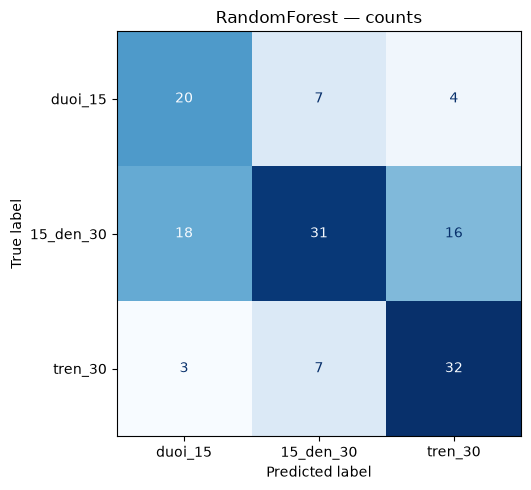

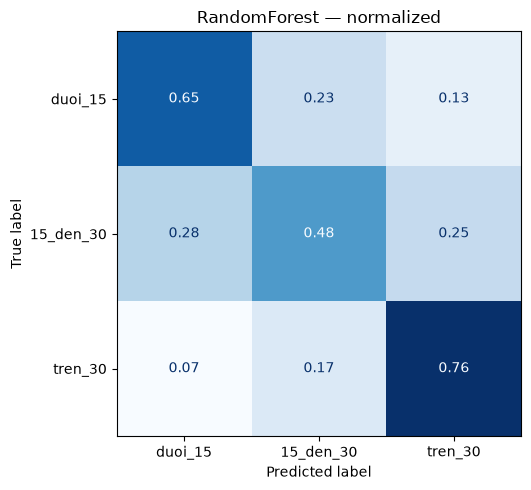

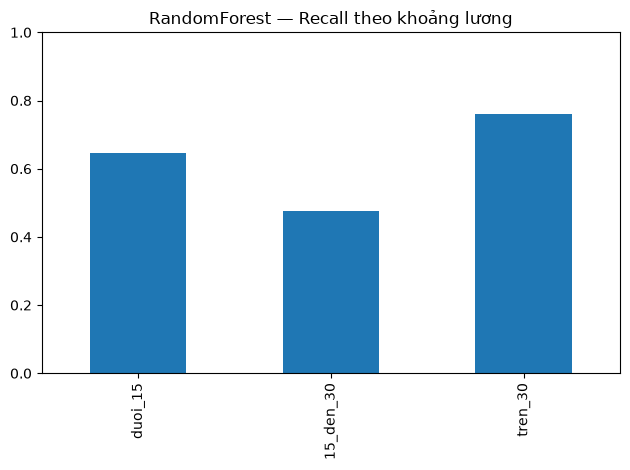

In [5]:
rows = []
for name, search in searches.items():
    model = search.best_estimator_
    pt, pv = model.predict(X_train), model.predict(X_test)
    train_f1 = f1_score(y_train, pt, labels=LABELS, average="macro", zero_division=0)
    test_f1 = f1_score(y_test, pv, labels=LABELS, average="macro", zero_division=0)
    b = search.best_index_
    rows.append({"model": name,
        "accuracy": accuracy_score(y_test, pv),
        "macro_precision": precision_score(y_test, pv, labels=LABELS, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, pv, labels=LABELS, average="macro", zero_division=0),
        "macro_f1": test_f1, "weighted_f1": f1_score(y_test, pv, average="weighted", zero_division=0),
        "train_macro_f1": train_f1, "gap": train_f1-test_f1,
        "cv_macro_f1": search.best_score_,
        "cv_train_macro_f1": search.cv_results_["mean_train_score"][b],
        "cv_std": search.cv_results_["std_test_score"][b]})
    report = pd.DataFrame(classification_report(y_test, pv, labels=LABELS,
                                              output_dict=True, zero_division=0)).T
    save_table(report, f"classification_report_{name}.csv", index=True)
comparison = pd.DataFrame(rows)
save_table(comparison, "model_comparison.csv")
display(comparison)
pred = winner.predict(X_test)
cm = confusion_matrix(y_test, pred, labels=LABELS)
assert cm.sum() == len(y_test)
assert cm.trace() == (pred == y_test.to_numpy()).sum()
save_table(pd.DataFrame(cm, index=LABELS, columns=LABELS), "confusion_matrix.csv", index=True)
for norm, suffix in [(None, "counts"), ("true", "normalized")]:
    fig, ax = plt.subplots(figsize=(7, 5))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=LABELS, normalize=norm,
        ax=ax, cmap="Blues", values_format="d" if norm is None else ".2f", colorbar=False)
    ax.set_title(f"{winner_name} — {suffix}")
    fig.tight_layout()
    fig.savefig(RESULT_DIR / "figures" / f"confusion_{suffix}.png", dpi=160)
    plt.show()
report = pd.DataFrame(classification_report(y_test, pred, labels=LABELS, output_dict=True, zero_division=0)).T
save_table(report.loc[LABELS], "recall_by_class.csv", index=True)
ax = report.loc[LABELS, "recall"].plot.bar(ylim=(0, 1), title=f"{winner_name} — Recall theo khoảng lương")
ax.figure.tight_layout()
ax.figure.savefig(RESULT_DIR / "figures" / "recall_by_class.png", dpi=160)
plt.show()


## 5. Cây cắt tỉa và các tin dự đoán sai

Nhóm giữ phần vẽ cây và thống kê lỗi của bản trước. Hình chỉ hiển thị các tầng đầu để dễ đọc; độ sâu và số lá in bên dưới là của toàn bộ cây.

Đối với bài toán này, dưới 15 triệu bị dự đoán trên 30 triệu (hoặc ngược lại) được xem là sai lệch hai bậc. Nhóm ưu tiên các lỗi này, sau đó xét điểm xác suất của mô hình. Điểm xác suất chưa được hiệu chỉnh, không phải độ tin cậy đã kiểm định.

Sau khi chạy mô hình, nhóm chọn tối đa 5 tin sai thực tế để đọc lại toàn bộ JD. Nhận xét được lưu riêng cùng dấu nhận dạng của dữ liệu và lần chia; nếu dữ liệu, mô hình hoặc danh sách test thay đổi, notebook yêu cầu rà lại thay vì dùng nhận xét cũ.


Cây có cắt tỉa: {'model__ccp_alpha': 0.01, 'model__max_depth': 3, 'model__min_samples_leaf': 3} depth= 3 leaves= 6
Dấu nhận dạng lần phân tích lỗi: f4a7c7f867fbb6ff0d1b4b8ad39f20e934f0b019248d00720eadc8bc67260244

TIN CẦN PHÂN TÍCH: vietnamworks-7fe0717a04 CG Phát Triển Giải Pháp CNTT - ID9280
Thật / dự đoán: duoi_15 / tren_30
Trung điểm lương: 12500000.0 ; skills: [".net", "agile", "aws", "c#", "ci/cd", "devops", "docker", "gitlab", "java", "jira", "kafka", "microservices", "rest api", "scrum", "spring boot"]
Kinh nghiệm min/max: 10.0 nan
JD: Mô tả công việc I. JOB PURPOSE Đóng vai trò chuyên gia kỹ thuật trong việc thiết kế và phát triển các giải pháp số cho khách hàng doanh nghiệp, đảm nhậm vai trò technical lead trong các team Agile, định hướng kiến trúc và thực hành phát triển nhằm đảm bảo tiến độ, chất lượng sản phẩm và sự phù hợp với chiến lược chuyển đổi số của tổ chức. II. CRITICAL ACCOUNTABILITIES 1. Dẫn dắt thiết kế và triển khai các giải pháp phức tạp, đảm bảo giải pháp đáp

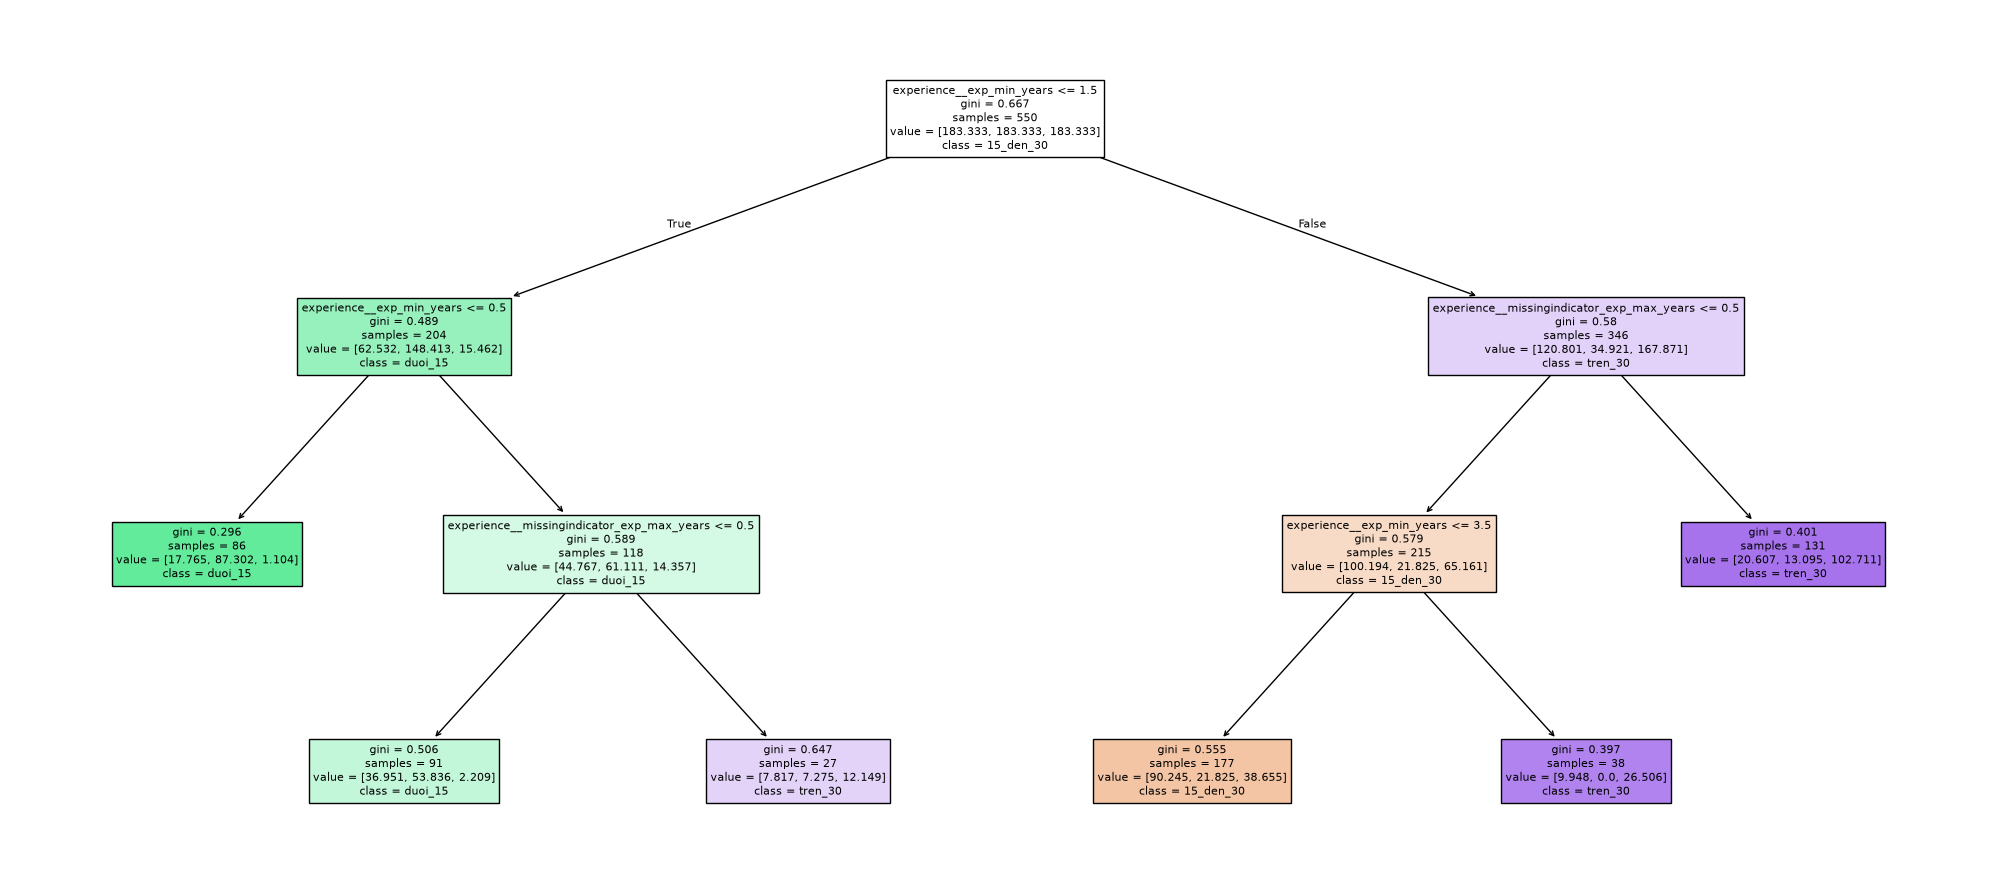

,source_row,job_uid,scope_status,title,source,URL_Goc,skills,exp_min_years,exp_max_years,Luong_TB,true_class,pred_class,confidence,ordinal_error,analysis_note
644,2879,vietnamworks-7fe0717a04,included_provisional,CG Phát Triển Giải Pháp CNTT - ID9280,vietnamworks,https://www.vietnamworks.com/cg-phat-trien-gia...,"["".net"", ""agile"", ""aws"", ""c#"", ""ci/cd"", ""devop...",10.0,NaN,12500000.0,duoi_15,tren_30,0.746971,2,
387,1991,topcv-0114f2dcbe,included_provisional,FRESHER Transmission Engineer Bitel (Viettel P...,topcv,https://www.topcv.vn/viec-lam/fresher-transmis...,"[""autocad"", ""cisco"", ""excel"", ""firewall"", ""vis...",0.0,NaN,35000000.0,tren_30,duoi_15,0.678395,2,
582,2509,topcv-033a519fc3,included_provisional,Kỹ Sư An Toàn Thông Tin,topcv,https://www.topcv.vn/viec-lam/ky-su-an-toan-th...,"[""cisco"", ""cybersecurity"", ""linux"", ""windows s...",1.0,1.0,32500000.0,tren_30,duoi_15,0.638084,2,
615,2703,vietnamworks-03cddaef4c,included_provisional,"Research & Teaching Assistants, Computer Scien...",vietnamworks,https://www.vietnamworks.com/research-and-teac...,"[""agile"", ""c#"", ""c++"", ""computer vision"", ""dee...",NaN,NaN,40500000.0,tren_30,duoi_15,0.529392,2,
591,2544,topdev-13fa7c7f57,included_provisional,NHÂN VIÊN TRIỂN KHAI BẢO TRÌ PHẦN MỀM,topdev,https://topdev.vn/detail-jobs/nhan-vien-trien-...,[],NaN,NaN,6500000.0,duoi_15,tren_30,0.398501,2,
679,3081,vietnamworks-cd010d6c77,included_provisional,[Tuyển Gấp] Test Engineer (Kỹ Sư Phòng Thử Ngh...,vietnamworks,https://www.vietnamworks.com/tuyen-gap-test-en...,[],NaN,NaN,11500000.0,duoi_15,tren_30,0.398501,2,
608,2655,vietnamworks-25fd4a65ed,included_provisional,Nhân Viên IT - Quản Trị Hệ Thống (Nhà Máy Đông...,vietnamworks,https://www.vietnamworks.com/nhan-vien-it-quan...,"[""cisco""]",NaN,NaN,13500000.0,duoi_15,tren_30,0.391440,2,
537,2382,topcv-1fe6e622d0,included_provisional,Kỹ Thuật Viên Máy Tính Và Thiết Bị Văn Phòng,topcv,https://www.topcv.vn/viec-lam/ky-thuat-vien-ma...,[],0.0,NaN,15000000.0,15_den_30,duoi_15,0.825926,1,
360,1925,topcv-9b2d453f21,included_provisional,Nhân Viên Tư Vấn Công Nghệ Thông Tin Fresher T...,topcv,https://www.topcv.vn/viec-lam/nhan-vien-tu-van...,"[""crm""]",0.0,NaN,17500000.0,15_den_30,duoi_15,0.817991,1,
409,2038,topcv-05e371f665,included_provisional,Nhân Viên Tư Vấn Công Nghệ Thông Tin Thu Nhập ...,topcv,https://www.topcv.vn/viec-lam/nhan-vien-tu-van...,"[""crm""]",0.0,NaN,17500000.0,15_den_30,duoi_15,0.817991,1,


In [6]:
dt_search = searches["DecisionTree"]
cv_dt = pd.DataFrame(dt_search.cv_results_)
pruned_rows = cv_dt[cv_dt["param_model__ccp_alpha"].astype(float).gt(0)]
pruned_params = pruned_rows.loc[pruned_rows["mean_test_score"].idxmax(), "params"]
from sklearn.base import clone
pruned = clone(dt_search.estimator).set_params(**pruned_params).fit(X_train, y_train)
tree = pruned.named_steps["model"]
print("Cây có cắt tỉa:", pruned_params, "depth=", tree.get_depth(), "leaves=", tree.get_n_leaves())
save_table(pd.DataFrame([{"params": json.dumps(pruned_params), "depth": tree.get_depth(),
                         "leaves": tree.get_n_leaves()}]), "pruned_tree_structure.csv")
fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(tree, max_depth=3, filled=True, class_names=list(tree.classes_), ax=ax,
          feature_names=list(pruned.named_steps["features"].get_feature_names_out()))
fig.tight_layout()
fig.savefig(RESULT_DIR / "figures" / "pruned_tree_top_levels.png", dpi=140)
plt.show()
review_columns = [c for c in ["source_row", "job_uid", "scope_status", "title", "source", "URL_Goc", "skills",
    "exp_min_years", "exp_max_years", "Luong_TB", "description_clean"] if c in data]
audit = data.iloc[test_idx][review_columns].copy()
audit["true_class"] = y_test.to_numpy()
audit["pred_class"] = pred
audit["confidence"] = winner.predict_proba(X_test).max(axis=1)
rank = {label: i for i, label in enumerate(LABELS)}
audit["ordinal_error"] = (audit["true_class"].map(rank)-audit["pred_class"].map(rank)).abs()
audit["analysis_note"] = ""  # Bổ sung nhận xét sau khi đọc từng tin, không tự suy diễn nguyên nhân.
save_table(audit, "test_predictions.csv")
errors = audit[audit["true_class"] != audit["pred_class"]].sort_values(
    ["ordinal_error", "confidence"], ascending=False)
save_table(errors, "misclassified_jobs.csv")
pairs = errors.groupby(["true_class", "pred_class"]).size().reset_index(name="count").sort_values("count", ascending=False)
save_table(pairs, "top_confusion_pairs.csv")
display(errors.drop(columns=["description_clean"], errors="ignore").head(10))

# Chọn từ kết quả hiện tại, không lấy danh sách bốn ID của bản 761 tin.
review_candidates = errors.head(5).copy()
save_table(review_candidates, "review_candidates.csv")
review_context = {
    "data_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "scope_filter": "included_provisional",
    "seed": SEED,
    "winner": winner_name,
    "winner_params": searches[winner_name].best_params_,
    "test_job_uids": data.iloc[test_idx]["job_uid"].astype(str).tolist(),
    "candidate_job_uids": review_candidates["job_uid"].astype(str).tolist(),
    "sklearn": sklearn.__version__,
}
review_fingerprint = hashlib.sha256(
    json.dumps(review_context, sort_keys=True, ensure_ascii=False).encode("utf-8")
).hexdigest()
print("Dấu nhận dạng lần phân tích lỗi:", review_fingerprint)
for _, row in review_candidates.iterrows():
    print("\nTIN CẦN PHÂN TÍCH:", row["job_uid"], row["title"])
    print("Thật / dự đoán:", row["true_class"], "/", row["pred_class"])
    print("Trung điểm lương:", row["Luong_TB"], "; skills:", row["skills"])
    print("Kinh nghiệm min/max:", row["exp_min_years"], row["exp_max_years"])
    print("JD:", row["description_clean"])


## 5b. Khảo sát overfitting và cắt tỉa cây bằng `ccp_alpha`

Đề yêu cầu Decision Tree **kèm cắt tỉa `ccp_alpha`** và **khảo sát overfitting**. Lưới ở mục 3 chỉ thử ba giá trị alpha (0; 0,001; 0,01) và đã giới hạn `max_depth`, nên không tách được tác dụng của riêng việc cắt tỉa. Mục này làm thí nghiệm riêng:

1. Học một **cây không giới hạn độ sâu** trên train và lấy dãy alpha thật bằng `cost_complexity_pruning_path` (mỗi alpha ứng với một lần cắt một nhánh yếu nhất).
2. Với từng alpha, tính Macro F1 trên phần train và phần validation của **đúng 3 fold dùng chung** ở mục 2.
3. Chọn alpha có Macro F1 validation cao nhất; nếu bằng nhau thì lấy alpha lớn hơn (cây gọn hơn).
4. So sánh cây đầy đủ (alpha = 0) với cây đã cắt tỉa: độ sâu, số lá, F1 train, F1 CV, F1 test và khoảng cách train–test.

Mục này **không** thay đổi mô hình đã chọn ở mục 3 hay danh sách tin sai ở mục 5; điểm test chỉ dùng để báo cáo, không dùng để chọn alpha.

Số giá trị alpha khảo sát: 94 | nhỏ nhất: 0.0 | lớn nhất: 0.04475


,cay,ccp_alpha,do_sau,so_la,train_macro_f1,cv_val_macro_f1,test_macro_f1,gap_train_test
0,Cây đầy đủ (alpha = 0),0.000000,33,248,0.957942,0.593627,0.536752,0.421189
1,Cây cắt tỉa (alpha chọn bằng CV),0.008134,3,6,0.643785,0.628909,0.575761,0.068024


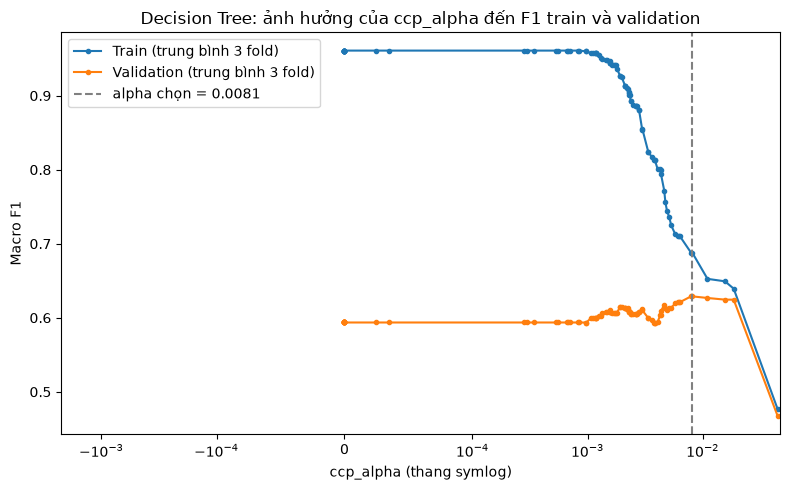

precision                      ...           f1                   
model     DecisionTree  Dummy RandomForest  ... DecisionTree Dummy RandomForest
class                                       ...                                
duoi_15          0.467  0.000        0.488  ...        0.553  0.00        0.556
15_den_30        0.625  0.471        0.689  ...        0.531  0.64        0.564
tren_30          0.622  0.000        0.615  ...        0.644  0.00        0.681

[3 rows x 9 columns]

experience__exp_min_years                     0.739
experience__missingindicator_exp_max_years    0.261
dtype: float64

In [7]:
from sklearn.base import clone

# (1) Dãy alpha từ cây đầy đủ. Bộ mã hóa đặc trưng chỉ học trên train.
full_pipe = pipeline(DecisionTreeClassifier(random_state=SEED, class_weight="balanced"))
features_train = clone(full_pipe.named_steps["features"]).fit_transform(X_train)
ccp_path = full_pipe.named_steps["model"].cost_complexity_pruning_path(features_train, y_train)
alphas = np.unique(ccp_path.ccp_alphas[:-1])   # bỏ alpha cuối: cây chỉ còn nút gốc
print("Số giá trị alpha khảo sát:", len(alphas), "| nhỏ nhất:", alphas.min(), "| lớn nhất:", round(alphas.max(), 5))

# (2) F1 train/validation trên 3 fold dùng chung cho từng alpha
survey_rows = []
for a in alphas:
    res = cross_validate(clone(full_pipe).set_params(model__ccp_alpha=a), X_train, y_train,
                         cv=folds, scoring=macro, return_train_score=True)
    survey_rows.append({"ccp_alpha": a,
                        "cv_train_macro_f1": res["train_score"].mean(),
                        "cv_val_macro_f1": res["test_score"].mean(),
                        "cv_val_std": res["test_score"].std()})
survey = pd.DataFrame(survey_rows)
save_table(survey, "pruning_path_cv.csv")

# (3) Chọn alpha theo validation; hòa thì lấy alpha lớn hơn
best_val = survey["cv_val_macro_f1"].max()
best_alpha = survey.loc[np.isclose(survey["cv_val_macro_f1"], best_val), "ccp_alpha"].max()

# (4) Cây đầy đủ và cây cắt tỉa, fit lại trên toàn train
full_model = clone(full_pipe).fit(X_train, y_train)
pruned_model = clone(full_pipe).set_params(model__ccp_alpha=best_alpha).fit(X_train, y_train)
full_tree = full_model.named_steps["model"]
pruned_tree = pruned_model.named_steps["model"]
overfit_rows = []
for label, model, a in [("Cây đầy đủ (alpha = 0)", full_model, 0.0),
                        ("Cây cắt tỉa (alpha chọn bằng CV)", pruned_model, best_alpha)]:
    t = model.named_steps["model"]
    cv_row = survey.iloc[(survey["ccp_alpha"] - a).abs().argmin()]
    train_f1 = f1_score(y_train, model.predict(X_train), labels=LABELS, average="macro", zero_division=0)
    test_f1 = f1_score(y_test, model.predict(X_test), labels=LABELS, average="macro", zero_division=0)
    overfit_rows.append({"cay": label, "ccp_alpha": a, "do_sau": t.get_depth(), "so_la": t.get_n_leaves(),
                         "train_macro_f1": train_f1, "cv_val_macro_f1": cv_row["cv_val_macro_f1"],
                         "test_macro_f1": test_f1, "gap_train_test": train_f1 - test_f1})
overfit_table = pd.DataFrame(overfit_rows)
save_table(overfit_table, "overfitting_full_vs_pruned.csv")
display(overfit_table)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(survey["ccp_alpha"], survey["cv_train_macro_f1"], marker=".", label="Train (trung bình 3 fold)")
ax.plot(survey["ccp_alpha"], survey["cv_val_macro_f1"], marker=".", label="Validation (trung bình 3 fold)")
ax.axvline(best_alpha, color="gray", linestyle="--", label=f"alpha chọn = {best_alpha:.4f}")
ax.set_xscale("symlog", linthresh=1e-4)
ax.set_xlabel("ccp_alpha (thang symlog)"); ax.set_ylabel("Macro F1")
ax.set_title("Decision Tree: ảnh hưởng của ccp_alpha đến F1 train và validation")
ax.legend(); fig.tight_layout()
fig.savefig(RESULT_DIR / "figures" / "pruning_curve.png", dpi=160)
plt.show()

# Precision / Recall / F1 từng lớp của mọi mô hình trên test (đề yêu cầu Precision, Recall)
per_class = []
for name, search in searches.items():
    rep_ = classification_report(y_test, search.best_estimator_.predict(X_test), labels=LABELS,
                                 output_dict=True, zero_division=0)
    for label in LABELS:
        per_class.append({"model": name, "class": label, "precision": rep_[label]["precision"],
                          "recall": rep_[label]["recall"], "f1": rep_[label]["f1-score"],
                          "support": int(rep_[label]["support"])})
per_class = pd.DataFrame(per_class)
save_table(per_class, "per_class_metrics.csv")
display(per_class.pivot(index="class", columns="model", values=["precision", "recall", "f1"]).reindex(LABELS).round(3))

# Kỹ năng/đặc trưng mà cây cắt tỉa dùng nhiều nhất (giải thích mô hình khi vấn đáp)
names = pruned_model.named_steps["features"].get_feature_names_out()
importance = (pd.Series(pruned_tree.feature_importances_, index=names)
              .loc[lambda s: s.gt(0)].sort_values(ascending=False))
save_table(importance.rename("importance").rename_axis("feature").reset_index(), "pruned_tree_importance.csv")
display(importance.head(15).round(3))

### Cách đọc thí nghiệm cắt tỉa

Đọc số liệu của **lần Run All hiện tại** ở bảng mục 5b và `overfitting_full_vs_pruned.csv`; không giữ số cũ nếu môi trường hoặc dữ liệu thay đổi.

- So sánh F1 train với F1 validation để nhận biết overfitting. Khi alpha tăng quá mạnh, cây có thể underfit; không khẳng định gap luôn giảm đều.
- Alpha chọn từ CV, test chỉ dùng báo cáo. Đây là thí nghiệm bổ sung, không thay mô hình đã chọn ở mục 3.
- Độ sâu, số lá và feature importance giúp giải thích cây; importance phản ánh cách chia nhánh, không chứng minh kỹ năng hay kinh nghiệm gây ra mức lương.
- RF và DT có điểm CV gần nhau trong lần đối chiếu, vì vậy nhóm không kết luận RF vượt trội ổn định. RF còn gap Train/Test cần trình bày như một hạn chế.


## 6. Tổng hợp kết quả và lưu môi trường

Bảng và nhận xét được tính theo tập sau lọc phạm vi, không giữ điểm của tập 761 tin. Nhóm chọn mô hình dựa trên CV, sau đó mới dùng test để đánh giá.

Nhận xét lỗi là phân tích thủ công dựa trên JD, không phải kết luận nhân quả tự động. Các trường hợp đã đọc chỉ được dùng khi dấu nhận dạng lần chạy còn khớp. Sau khi phân tích lỗi, không điều chỉnh mô hình theo chính test này rồi báo lại như một đánh giá độc lập.

Kết quả chỉ áp dụng cho các tin thuộc phạm vi IT sơ bộ và đủ điều kiện lương. Nhóm còn hạn chế ở kỹ năng trích xuất, kinh nghiệm thiếu và khả năng phát hiện tin gần trùng. Phiên bản thư viện được ghi vào `requirements.txt`; cấu hình và cách chia được lưu trong JSON và `split_manifest.csv`.

Để chạy lại, kiểm tra đường dẫn rồi chọn **Restart Kernel → Run All**. Khi đổi dữ liệu hoặc thư viện, cần kiểm tra lại số mẫu, chỉ số và các tin sai. Kết quả luôn xuất vào `output_salary_scope` cạnh notebook, dù kernel đang chạy từ gốc repo hay thư mục notebook.


In [8]:
config = {
    # Chỉ ghi đường dẫn tương đối: không lộ tên người dùng/ổ đĩa của máy chạy.
    "data_path_relative_to_project": DATA_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "notebook_dir_relative_to_project": NOTEBOOK_DIR.relative_to(PROJECT_ROOT).as_posix() if NOTEBOOK_DIR.is_relative_to(PROJECT_ROOT) else NOTEBOOK_DIR.name,
    "data_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "python": platform.python_version(), "pandas": pd.__version__,
    "numpy": np.__version__, "sklearn": sklearn.__version__,
    "seed": SEED, "features": FEATURES,
    "target": "salary_class", "salary_unit": "VND/month; verify upstream normalization",
    "target_meaning": "class of midpoint of advertised salary range; not take-home pay",
    "scope_filter": "included_provisional",
    "salary_eligible_before_scope": int(salary_valid.sum()),
    "excluded_by_scope": int((salary_valid & ~scope_ok).sum()),
    "scope_counts": scope.fillna("missing").value_counts().to_dict(),
    "review_fingerprint": review_fingerprint,
    "boundaries": "<15000000; 15000000<=x<=30000000; >30000000",
    "samples": len(data), "train": len(train_idx), "test": len(test_idx),
    "grouping": "connected components of job_group_id or normalized description",
    "outer_split": "first fold of StratifiedGroupKFold(5,shuffle=True,random_state=42)",
    "inner_split": "shared materialized StratifiedGroupKFold(3,shuffle=True,random_state=42)",
    "winner_selected_by": "train CV macro F1", "winner": winner_name,
    "best_params": {name: search.best_params_ for name, search in searches.items()},
    "pruned_tree_params": pruned_params,
    "pruning_survey": {"n_alphas": int(len(alphas)), "best_alpha": float(best_alpha),
                       "full_tree": {"depth": int(full_tree.get_depth()), "leaves": int(full_tree.get_n_leaves())},
                       "pruned_tree": {"depth": int(pruned_tree.get_depth()), "leaves": int(pruned_tree.get_n_leaves())}},
}
(RESULT_DIR / "experiment_config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")

# Các nhận xét được bổ sung sau khi đọc review_candidates.csv của lần chạy này.
REVIEWED_FINGERPRINT = "f4a7c7f867fbb6ff0d1b4b8ad39f20e934f0b019248d00720eadc8bc67260244"
review_notes = {'vietnamworks-7fe0717a04': 'Quan sát: trung điểm lương trong CSV là 12,5 triệu, nhưng JD yêu cầu tối thiểu 10 năm CNTT, ít nhất 3 năm technical lead/kiến trúc và nhiều kỹ năng backend/cloud. Dự đoán nhóm cao có thể liên quan đến các đặc trưng này. Cần kiểm tra lại khoảng lương và nguồn quy đổi vì chúng có vẻ chưa phù hợp với mô tả vai trò; chưa đủ bằng chứng để kết luận nhãn sai và không tự sửa nhãn theo mô hình.', 'topcv-0114f2dcbe': 'Quan sát: tin ghi Fresher, không cần kinh nghiệm, exp_min=0; JD nêu làm tại Peru và tổng thu nhập khoảng 1.200–1.500 USD/tháng. Giả thuyết: mô hình chỉ có skills/experience nên chưa thể hiện bối cảnh làm việc nước ngoài và thành phần thu nhập. Cần rà phạm vi thị trường Việt Nam và quy đổi lương ở bước đầu nguồn. Chưa tự loại tin chỉ vì dự đoán sai; mọi quy tắc địa lý mới phải áp dụng chung rồi đánh giá lại.', 'topcv-033a519fc3': 'Quan sát: trung điểm lương 32,5 triệu, kinh nghiệm trong dữ liệu là 1/1 năm; skills hiện có Cisco, Cybersecurity, Linux, Windows Server. JD có thêm CCNA, CompTIA Security+, pentest, vulnerability assessment, mã hóa và quản lý truy cập. Giả thuyết: bộ trích kỹ năng chưa phản ánh đầy đủ yêu cầu an toàn thông tin. Cần rà extractor trên dữ liệu phát triển; không khẳng định đây là nguyên nhân duy nhất.', 'vietnamworks-03cddaef4c': 'Quan sát: trung điểm lương 40,5 triệu, thiếu cả hai trường kinh nghiệm; JD yêu cầu bằng thạc sĩ, tiếng Anh IELTS, nghiên cứu/giảng dạy về deep learning và computer vision. X chỉ chứa kỹ năng công nghệ và kinh nghiệm nên chưa phản ánh hết trình độ học thuật và nhiệm vụ nghiên cứu. Đây là giới hạn biểu diễn đầu vào; nếu mở rộng đặc trưng cần phù hợp yêu cầu đề và một đánh giá độc lập.', 'topdev-13fa7c7f57': 'Quan sát: skills rỗng và cả hai trường kinh nghiệm đều thiếu; JD ghi lương 6–7 triệu cộng thưởng, phù hợp trung điểm 6,5 triệu trong CSV. Tin mô tả triển khai phần mềm, hỗ trợ người dùng, nghiệp vụ và giao tiếp. Giả thuyết: đầu vào quá ít thông tin sau trích xuất và điền median nên mô hình phân biệt kém. Cần rà kỹ năng hỗ trợ/triển khai và bổ sung cờ thiếu kỹ năng nếu được đánh giá bằng CV; không đọc mức lương trong JD để làm X.'}
if REVIEWED_FINGERPRINT != review_fingerprint:
    print("Lần chạy đã thay đổi hoặc chưa được rà lỗi: không dùng lại nhận xét cũ. Đọc review_candidates.csv để cập nhật.")
    active_notes = {}
else:
    active_notes = {uid: note for uid, note in review_notes.items()
                    if uid in set(review_candidates["job_uid"])}
errors["analysis_note"] = errors["job_uid"].map(active_notes).fillna("")
save_table(errors, "misclassified_jobs.csv")
reviewed = errors[errors["analysis_note"].ne("")]
save_table(reviewed, "reviewed_errors.csv")
summary = comparison.to_string(index=False, float_format=lambda v: f"{v:.4f}")
lines = ["BƯỚC 2.5 — PHÂN LỚP TRUNG ĐIỂM KHOẢNG LƯƠNG CHÀO TUYỂN IT", "",
    f"Nguồn: {DATA_PATH.relative_to(PROJECT_ROOT).as_posix()} (đường dẫn tương đối từ gốc repo)",
    f"Dữ liệu gốc: {len(df)}; đủ điều kiện: {len(data)}; train: {len(train_idx)}; test: {len(test_idx)}.",
    "Nhãn: <15 triệu; 15–30 triệu gồm hai đầu; >30 triệu. Đơn vị mục tiêu VND/tháng, cần đối chiếu quy tắc chuẩn hóa đầu nguồn.",
    f"Phân bố: {data['salary_class'].value_counts().to_dict()}",
    f"Trước lọc phạm vi: {int(salary_valid.sum())} tin đủ điều kiện lương; tạm loại {int((salary_valid & ~scope_ok).sum())} tin chưa được chấp nhận trong phạm vi IT.",
    "Chỉ giữ scope_status=included_provisional. Đây là phạm vi sơ bộ, không khẳng định tất cả tin pending_review đều ngoài IT.",
    "Luong_TB là trung điểm khoảng lương chào tuyển đã xử lý, không phải lương thực nhận.",
    "X chỉ gồm skills, exp_min_years, exp_max_years. Lương, tiêu đề và mô tả không vào X.",
    "Kỹ năng multi-hot; median và chỉ báo thiếu học trong pipeline từng fold.",
    "Nhóm là thành phần liên thông của job_group_id hoặc mô tả chuẩn hóa giống nhau; không có nhóm giao nhau train/test hoặc train/validation.",
    "Chưa phát hiện hết tin gần trùng. Ba mô hình dùng chung 3 fold CV trên train.",
    f"Chọn mô hình bằng CV Macro F1: {winner_name}. Không chọn lại bằng test.", "", summary, "",
    f"Cây cắt tỉa: {pruned_params}; độ sâu {tree.get_depth()}, số lá {tree.get_n_leaves()}.",
    "CV tìm cả alpha=0 và alpha>0. Nếu cấu hình DT tốt nhất có alpha=0, cây cắt tỉa bổ sung không được gọi là DT tốt nhất.",
    "Train là điểm fit lại trên toàn train; gap lớn cảnh báo overfitting. So sánh thêm CV train/validation và độ lệch chuẩn, không chỉ test.",
    "", "KHẢO SÁT OVERFITTING VÀ CẮT TỈA (mục 5b)",
    f"Dãy alpha lấy từ cost_complexity_pruning_path của cây không giới hạn độ sâu: {len(alphas)} giá trị; chọn alpha bằng CV Macro F1 = {best_alpha:.5f}.",
    overfit_table.to_string(index=False, float_format=lambda v: f"{v:.4f}"),
    "", "PHÂN TÍCH TIN SAI CỤ THỂ"]
for _, row in reviewed.iterrows():
    lines += ["", f"{row['job_uid']} — {row['title']}",
        f"Thật: {row['true_class']}; dự đoán: {row['pred_class']}; lương: {row['Luong_TB']:,.0f} VND/tháng.",
        f"Skills: {row['skills']}; kinh nghiệm min/max: {row['exp_min_years']}/{row['exp_max_years']}.",
        row["analysis_note"]]
lines += ["", "HẠN CHẾ VÀ HƯỚNG PHÁT TRIỂN",
    "Kết quả chỉ phản ánh tin công khai lương đủ điều kiện, chưa đại diện toàn bộ thị trường. Lương/thu nhập, quy đổi ngoại tệ/kỳ lương và nhãn gần ngưỡng cần được kiểm tra từ dữ liệu gốc.",
    "Các nguyên nhân lỗi là giả thuyết dựa trên JD. Không sửa extractor hoặc tham số dựa test hiện tại rồi coi điểm test đó là đánh giá độc lập mới; dùng tập kiểm tra mới hoặc nested CV khi đánh giá phiên bản sau.",
    "Cần cải thiện độ đầy đủ của skills/experience bằng quy tắc chung; không đưa cột lương hay văn bản chứa lương vào X để tăng điểm.",
    "Bước này kế thừa dữ liệu processed của 2.1–2.2. Chưa kiểm tra kết quả Clustering/Apriori trong lần này nên không tự tạo liên hệ định lượng với 2.3–2.4.",
    "", "TÁI LẬP",
    "Restart & Run All từ kernel sạch. Xem experiment_config.json để đối chiếu seed, phiên bản thư viện, hash CSV và cấu hình; split_manifest.csv để kiểm tra chia tập.",
    "Bảng/hình đều được tính từ cùng lần chạy. Điểm có thể thay đổi khi đổi dữ liệu hoặc phiên bản thư viện."]
report_text = "\n".join(lines)
(RESULT_DIR / "MiniNote_salary_final.txt").write_text(report_text, encoding="utf-8")
print(report_text)
print("\nĐã xuất kết quả vào:", RESULT_DIR.name, "(cạnh notebook)")
display(reviewed[["job_uid", "true_class", "pred_class", "Luong_TB", "analysis_note"]])

# Chốt các phiên bản cần để chạy lại; không cài hoặc thay thư viện trong notebook.
from importlib.metadata import version
packages = ["numpy", "pandas", "matplotlib", "scikit-learn", "ipython"]
requirements_text = "# Môi trường đã chạy; Python " + platform.python_version() + "\n"
requirements_text += "\n".join(f"{package}=={version(package)}" for package in packages) + "\n"
(RESULT_DIR / "requirements.txt").write_text(requirements_text, encoding="utf-8")
print("\nSố tin sai đã được nhận xét trong lần chạy này:", len(reviewed))
if len(reviewed) < min(3, len(errors)):
    print("Cần đọc lại các tin sai và bổ sung nhận xét trước khi chốt báo cáo.")

# Nhận xét ngắn theo đúng số liệu của lần chạy hiện tại.
cv_ranking = comparison.sort_values("cv_macro_f1", ascending=False)
chosen_result = comparison.set_index("model").loc[winner_name]
cv_difference = float(cv_ranking.iloc[0]["cv_macro_f1"] - cv_ranking.iloc[1]["cv_macro_f1"])
conclusion = (
    f"\nKẾT QUẢ SAU LỌC PHẠM VI IT\n"
    f"Giữ {len(data)} tin; train {len(train_idx)}, test {len(test_idx)}.\n"
    f"Chọn {winner_name} bằng CV. Accuracy test={chosen_result['accuracy']:.4f}; "
    f"Macro F1 test={chosen_result['macro_f1']:.4f}; gap={chosen_result['gap']:.4f}.\n"
    f"Chênh lệch CV Macro F1 giữa hai mô hình dẫn đầu={cv_difference:.6f}. "
    "Chênh lệch nhỏ chưa cho thấy mô hình dẫn đầu vượt trội ổn định; cần đọc cùng CV Std.\n"
    "Khoảng cách train/test vẫn cần được lưu ý. Không so điểm với tập 761 tin để kết luận cải thiện, "
    "vì dữ liệu và phép chia đã thay đổi.\n"
    "Một ví dụ lỗi là việc tại Peru; scope_status kiểm soát phạm vi ngành sơ bộ, chưa tự đảm bảo phạm vi địa lý. "
    "Cần làm rõ phạm vi thị trường với nhóm trước thí nghiệm tiếp theo, không thay quy tắc theo từng lỗi test.\n"
)
print(conclusion)
with (RESULT_DIR / "MiniNote_salary_final.txt").open("a", encoding="utf-8") as file:
    file.write(conclusion)


BƯỚC 2.5 — PHÂN LỚP TRUNG ĐIỂM KHOẢNG LƯƠNG CHÀO TUYỂN IT

Nguồn: buoc2.1_2.2/data/processed/clean_data_processed.csv (đường dẫn tương đối từ gốc repo)
Dữ liệu gốc: 3135; đủ điều kiện: 688; train: 550; test: 138.
Nhãn: <15 triệu; 15–30 triệu gồm hai đầu; >30 triệu. Đơn vị mục tiêu VND/tháng, cần đối chiếu quy tắc chuẩn hóa đầu nguồn.
Phân bố: {'15_den_30': 323, 'tren_30': 208, 'duoi_15': 157}
Trước lọc phạm vi: 761 tin đủ điều kiện lương; tạm loại 73 tin chưa được chấp nhận trong phạm vi IT.
Chỉ giữ scope_status=included_provisional. Đây là phạm vi sơ bộ, không khẳng định tất cả tin pending_review đều ngoài IT.
Luong_TB là trung điểm khoảng lương chào tuyển đã xử lý, không phải lương thực nhận.
X chỉ gồm skills, exp_min_years, exp_max_years. Lương, tiêu đề và mô tả không vào X.
Kỹ năng multi-hot; median và chỉ báo thiếu học trong pipeline từng fold.
Nhóm là thành phần liên thông của job_group_id hoặc mô tả chuẩn hóa giống nhau; không có nhóm giao nhau train/test hoặc train/validation.


,job_uid,true_class,pred_class,Luong_TB,analysis_note
644,vietnamworks-7fe0717a04,duoi_15,tren_30,12500000.0,"Quan sát: trung điểm lương trong CSV là 12,5 t..."
387,topcv-0114f2dcbe,tren_30,duoi_15,35000000.0,"Quan sát: tin ghi Fresher, không cần kinh nghi..."
582,topcv-033a519fc3,tren_30,duoi_15,32500000.0,"Quan sát: trung điểm lương 32,5 triệu, kinh ng..."
615,vietnamworks-03cddaef4c,tren_30,duoi_15,40500000.0,"Quan sát: trung điểm lương 40,5 triệu, thiếu c..."
591,topdev-13fa7c7f57,duoi_15,tren_30,6500000.0,Quan sát: skills rỗng và cả hai trường kinh ng...
